<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana15/RegresionLogistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/MyDrive/ColabNotebooks/Cursos/MetodosComputacionales2026')

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [58]:
df = pd.read_csv("Semana15/Data/Riesgo_Reprobacion_40_estudiantes.csv")
R = df["Riesgo"].to_numpy(dtype=float)
y = df["Reprobo"].to_numpy(dtype=float)

print(df.head())
print(f"Estudiantes: {len(y)} | Aprobaron: {sum(y == 0)} | Reprobaron: {sum(y == 1)}")

   Riesgo  Reprobo
0  0.4215        0
1  0.4302        0
2  0.3544        0
3  0.4619        0
4  0.4655        0
Estudiantes: 40 | Aprobaron: 22 | Reprobaron: 18


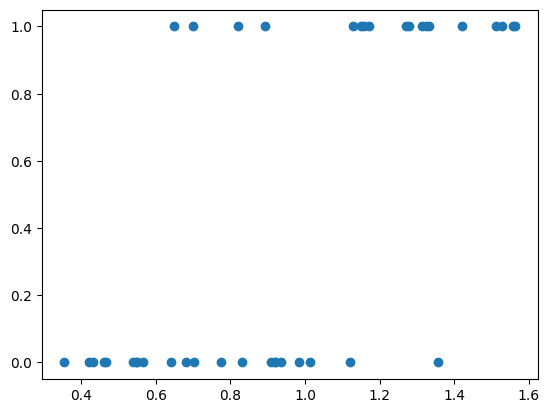

In [5]:
plt.scatter(R,y)

In [8]:
def sigmoide(b0,b1,R):
  z = b0 + b1*R
  return 1/(1+np.exp(-z))

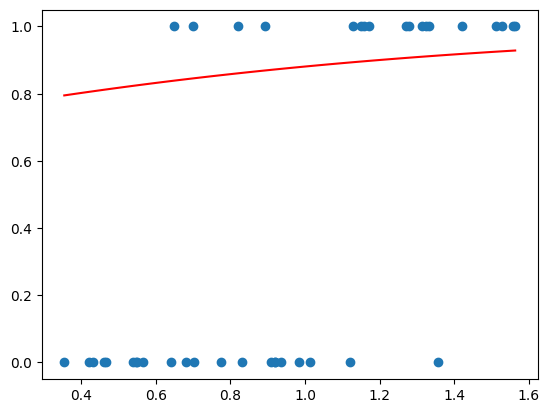

In [9]:
r = np.linspace(np.min(R),np.max(R),100)
plt.scatter(R,y)
plt.plot(r,sigmoide(1,1,r),color='r')

In [108]:
def Entropia(b0,b1,y,R):
  return -np.mean(y*np.log(sigmoide(b0,b1,R)) + (1-y)*np.log(1-sigmoide(b0,b1,R)))

In [117]:
# Stocastich gradient descent
# the batch size generates a fluctuation in the data space
epochs = 10000
b0, b1 = 10.,10.
gamma = 1e-2
Historial = []
for e in range(epochs):
  batch = np.random.randint(0,len(y),10)
  R1 = R[batch]
  y1 = y[batch]
  b0 = b0 - gamma*np.sum(sigmoide(b0,b1,R1) - y1)
  b1 = b1 - gamma*np.sum((sigmoide(b0,b1,R1) - y1)*R1)
  Historial.append(Entropia(b0,b1,y1,R1))

In [118]:
b0,b1

(np.float64(-5.6711071175163585), np.float64(5.5639370120647))

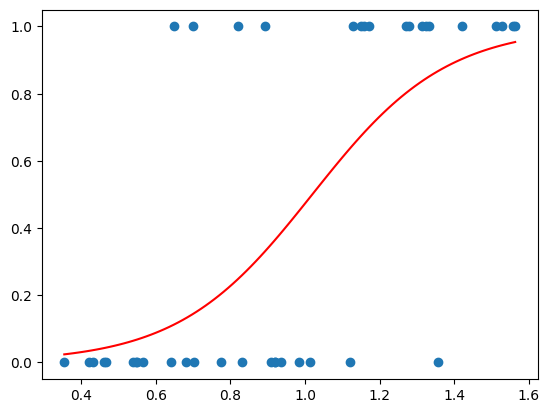

In [119]:
r = np.linspace(np.min(R),np.max(R),100)
plt.scatter(R,y)
plt.plot(r,sigmoide(b0,b1,r),color='r')

Text(0.5, 0, 'Epochs=10000')

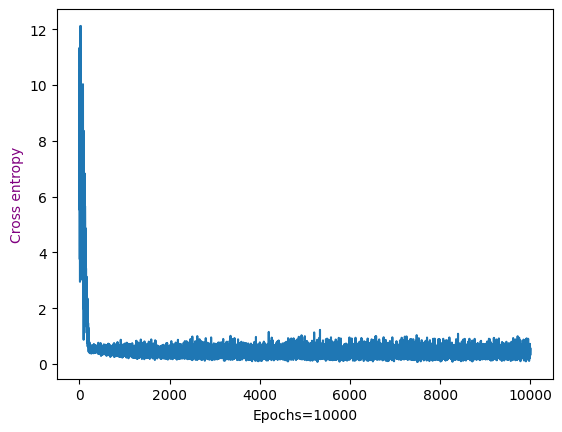

In [120]:
plt.plot(Historial)
plt.ylabel('Cross entropy',color='purple')
plt.xlabel('Epochs={0}'.format(epochs))


In [121]:
Historial[-1]

np.float64(0.346274646717454)